# Expert validation

Deferral rate and deferral types as the synthetic expert's accuracy varies (`tab:validation_deffer_rate`,
`tab:validation_type_trends`, `fig:expert_validation_rs`; appendix `tab:validation_results`,
`tab:counterfactual_coverage_runtime` and the composition figure).

630 runs: 3 datasets × 3 losses × 7 requested expert accuracies × 10 seeds. Each run trains
an L2D system on the decisions of a synthetic OpenL2D expert and searches a counterfactual
for every deferred test point (`core.run_validation`). Runs are cached in
`cache/validation/`, and the run cell only computes the missing ones.

`EXPERT` selects the expert model behind expected expert performance and the deferral
types; changing it needs no rerun. Outputs go to `figures/<EXPERT>/`.
The known-expert table of the appendix (`app:known_expert`) is `type_trends.tex` with
`EXPERT = "true"`; the last section compares the two expert models.

In [1]:
EXPERT = "fitted"  # "fitted": the expert fitted by MLE on each training split (paper); "true": the known synthetic expert

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from joblib import Parallel, delayed
from scipy import stats
from sklearn.metrics import roc_auc_score

import core

OUT = core.FIGURES / EXPERT
OUT.mkdir(parents=True, exist_ok=True)
CONFIGS = [(d, m, a, s) for d in core.DATASETS for m in core.METHODS for a in core.ACCURACIES for s in core.SEEDS]

## Runs

About 14 CPU-hours when nothing is cached. Each job uses one thread.

In [3]:
def job(function, *args):
    torch.set_num_threads(1)
    function(*args)


jobs = [delayed(job)(core.run_validation, *c) for c in CONFIGS if not core.is_cached(core.validation_path(*c))]
jobs += [delayed(job)(core.experts, d, a, s) for d in core.DATASETS for a in core.ACCURACIES for s in core.SEEDS
         if not core.expert_path(d, a, s).exists()]
print(f"{len(jobs)} jobs to run")
Parallel(n_jobs=-1, verbose=5)(jobs);

0 jobs to run


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.


## Deferral types with the selected expert

In [4]:
def summarize(dataset, method, accuracy, seed):
    pairs, info = core.load_run(core.validation_path(dataset, method, accuracy, seed))
    typed = core.assign_types(pairs, core.expert_model(dataset, accuracy, seed, EXPERT))
    found = typed["found"].to_numpy(bool)
    counts = typed.loc[found, "category"].value_counts()
    origin = (typed["uncertainty_x"] == typed["uncertainty_cf"]) & (typed["expert_error_x"] == typed["expert_error_cf"])
    shares = {t: counts.get(t, 0) / found.sum() if found.any() else np.nan for t in core.TYPES}
    return {**info, "n_found": int(found.sum()), **shares,
            "n_neither_off_origin": int((found & (typed["category"] == "neither") & ~origin).sum())}


summary = pd.DataFrame([summarize(*c) for c in CONFIGS])
summary["deferral_rate"] = summary["n_deferred"] / summary["n_test"]
summary["type_ii_mixed"] = summary["type_ii"] + summary["mixed"]


def select(method, dataset):
    return summary[(summary["method"] == method) & (summary["dataset"] == dataset)]

## Deferral-rate and type-share trends

Mean within-seed OLS slope in percentage points per +0.10 requested accuracy, with a
two-sided one-sample t-test of the ten seed slopes against zero.

In [5]:
def seed_slope(frame, outcome):
    slopes = []
    for _, seed_frame in frame.groupby("seed"):
        clean = seed_frame[["accuracy", outcome]].dropna()
        if clean["accuracy"].nunique() >= 2:
            slopes.append(np.polyfit(clean["accuracy"].to_numpy(float), clean[outcome].to_numpy(float), 1)[0] * 0.10 * 100.0)
    return float(np.mean(slopes)), float(stats.ttest_1samp(slopes, popmean=0.0).pvalue)


def cells(result):
    coefficient, p = result
    return [f"{coefficient:+.1f}", "$<0.001$" if p < 0.001 else f"${p:.3f}$"]


def tabular(columns, header, body):
    lines = [rf"\begin{{tabular}}{{{columns}}}", r"\toprule", *header, *body, r"\bottomrule", r"\end{tabular}"]
    return "\n".join(lines) + "\n"


def save(name, text):
    (OUT / name).write_text(text)
    print(text)


DATASET_HEADER = [
    r"\multirow{2}{*}{Method} & \multicolumn{2}{c}{Adult} & \multicolumn{2}{c}{Plant} & \multicolumn{2}{c}{Wine} \\",
    r"\cmidrule(lr){2-3} \cmidrule(lr){4-5} \cmidrule(lr){6-7}",
]
deferral = [" & ".join([core.METHOD_LABELS[m], *[c for d in core.DATASETS for c in cells(seed_slope(select(m, d), "deferral_rate"))]]) + r" \\"
            for m in core.METHODS]
save("deferral_rate_trends.tex", tabular(
    "lcccccc", DATASET_HEADER + [r" & Coef. (pp) & $p$ & Coef. (pp) & $p$ & Coef. (pp) & $p$ \\", r"\midrule"], deferral))

SHARES = {"Type I": "type_i", "Type II": "type_ii", "Mixed": "mixed", "Type II + Mixed": "type_ii_mixed"}
body = []
for m in core.METHODS:
    body.append(r"\midrule")
    for i, d in enumerate(core.DATASETS):
        method_cell = rf"\multirow[c]{{3}}{{*}}{{{core.METHOD_LABELS[m]}}}" if i == 0 else ""
        values = [c for column in SHARES.values() for c in cells(seed_slope(select(m, d), column))]
        body.append(" & ".join([method_cell, core.DATASET_LABELS[d], *values]) + r" \\")
save("type_trends.tex", tabular("llcccccccc", [
    r"\multirow{2}{*}{Method} & \multirow{2}{*}{Dataset} & " + " & ".join(rf"\multicolumn{{2}}{{c}}{{{s}}}" for s in SHARES) + r" \\",
    r"\cmidrule(lr){3-4} \cmidrule(lr){5-6} \cmidrule(lr){7-8} \cmidrule(lr){9-10}",
    r" & & " + " & ".join(["Coef. (pp) & $p$"] * 4) + r" \\",
], body))

\begin{tabular}{lcccccc}
\toprule
\multirow{2}{*}{Method} & \multicolumn{2}{c}{Adult} & \multicolumn{2}{c}{Plant} & \multicolumn{2}{c}{Wine} \\
\cmidrule(lr){2-3} \cmidrule(lr){4-5} \cmidrule(lr){6-7}
 & Coef. (pp) & $p$ & Coef. (pp) & $p$ & Coef. (pp) & $p$ \\
\midrule
Realizable Surrogate & +19.2 & $<0.001$ & +17.5 & $<0.001$ & +16.5 & $<0.001$ \\
Cross-Entropy Surrogate & +18.5 & $<0.001$ & +12.3 & $<0.001$ & +13.5 & $<0.001$ \\
One-vs-All & +17.7 & $<0.001$ & +15.5 & $<0.001$ & +13.5 & $<0.001$ \\
\bottomrule
\end{tabular}

\begin{tabular}{llcccccccc}
\toprule
\multirow{2}{*}{Method} & \multirow{2}{*}{Dataset} & \multicolumn{2}{c}{Type I} & \multicolumn{2}{c}{Type II} & \multicolumn{2}{c}{Mixed} & \multicolumn{2}{c}{Type II + Mixed} \\
\cmidrule(lr){3-4} \cmidrule(lr){5-6} \cmidrule(lr){7-8} \cmidrule(lr){9-10}
 & & Coef. (pp) & $p$ & Coef. (pp) & $p$ & Coef. (pp) & $p$ & Coef. (pp) & $p$ \\
\midrule
\multirow[c]{3}{*}{Realizable Surrogate} & Adult & -10.0 & $<0.001$ & +7.3 & $<0.0

## Appendix: accuracy and counterfactual coverage

Neither table depends on the expert model.

In [6]:
accuracy = [" & ".join([core.METHOD_LABELS[m], *[f"{select(m, d)[c].mean():.3f}" for d in core.DATASETS
                                                  for c in ("system_acc", "classifier_all_acc")]]) + r" \\"
            for m in core.METHODS]
save("accuracy.tex", tabular(
    "lcccccc", DATASET_HEADER + [r" & System & Classifier & System & Classifier & System & Classifier \\", r"\midrule"], accuracy))

body = []
for d in core.DATASETS:
    for i, m in enumerate(core.METHODS):
        frame = select(m, d)
        searched, found, seconds = frame["n_deferred"].sum(), frame["n_found"].sum(), frame["search_seconds"].sum()
        dataset_cell = rf"\multirow[c]{{3}}{{*}}{{{core.DATASET_LABELS[d]}}}" if i == 0 else ""
        body.append(f"{dataset_cell} & {core.METHOD_LABELS[m]} & {found:,} / {searched:,} & {100 * found / searched:.2f}\\% & "
                    f"{seconds / len(frame):.2f} & {1000 * seconds / searched:.2f} \\\\")
    body.append(r"\midrule" if d != core.DATASETS[-1] else "")
save("coverage.tex", tabular("llllll", [
    r" &  & \multicolumn{2}{c}{Counterfactual coverage} & \multicolumn{2}{c}{Search time} \\",
    r" &  & Found / searched & Hit rate & Mean / run (s) & Per 1,000 searched (s) \\",
    r"Dataset & Method &  &  &  &  \\", r"\midrule"], [line for line in body if line]))

\begin{tabular}{lcccccc}
\toprule
\multirow{2}{*}{Method} & \multicolumn{2}{c}{Adult} & \multicolumn{2}{c}{Plant} & \multicolumn{2}{c}{Wine} \\
\cmidrule(lr){2-3} \cmidrule(lr){4-5} \cmidrule(lr){6-7}
 & System & Classifier & System & Classifier & System & Classifier \\
\midrule
Realizable Surrogate & 0.904 & 0.818 & 0.900 & 0.807 & 0.857 & 0.721 \\
Cross-Entropy Surrogate & 0.903 & 0.798 & 0.898 & 0.626 & 0.857 & 0.627 \\
One-vs-All & 0.905 & 0.849 & 0.902 & 0.852 & 0.867 & 0.754 \\
\bottomrule
\end{tabular}

\begin{tabular}{llllll}
\toprule
 &  & \multicolumn{2}{c}{Counterfactual coverage} & \multicolumn{2}{c}{Search time} \\
 &  & Found / searched & Hit rate & Mean / run (s) & Per 1,000 searched (s) \\
Dataset & Method &  &  &  &  \\
\midrule
\multirow[c]{3}{*}{Adult} & Realizable Surrogate & 279,006 / 280,022 & 99.64\% & 24.44 & 6.11 \\
 & Cross-Entropy Surrogate & 360,229 / 384,195 & 93.76\% & 56.26 & 10.25 \\
 & One-vs-All & 339,090 / 339,319 & 99.93\% & 31.35 & 6.47 \\
\midrule


## Numbers quoted in the text

In [7]:
rates = [seed_slope(select(m, d), "deferral_rate")[0] for m in core.METHODS for d in core.DATASETS]
seconds = [1000 * select(m, d)["search_seconds"].sum() / select(m, d)["n_deferred"].sum() for m in core.METHODS for d in core.DATASETS]
print(f"Deferral rate slopes: {min(rates):.1f} to {max(rates):.1f} pp per +0.10 accuracy")
print(f"Counterfactuals found: {summary.n_found.sum():,} / {summary.n_deferred.sum():,} = {100 * summary.n_found.sum() / summary.n_deferred.sum():.2f}%")
print(f"Search time: {min(seconds):.2f} to {max(seconds):.2f} s per 1,000 searched")
print(f"Pairs with neither type, origin excluded: {100 * summary.n_neither_off_origin.sum() / summary.n_found.sum():.1f}% of found pairs")

Deferral rate slopes: 12.3 to 19.2 pp per +0.10 accuracy
Counterfactuals found: 1,221,616 / 1,285,196 = 95.05%
Search time: 4.17 to 13.17 s per 1,000 searched
Pairs with neither type, origin excluded: 3.6% of found pairs


## Fitted vs. known expert (appendix `app:known_expert`)

AUC of P(h(x)=1 | y, x) against the synthetic expert's decisions on the test split, for the known and
the fitted expert model, and the share of counterfactual pairs that both models assign the same deferral
type. Neither depends on `EXPERT`.

In [8]:
def expert_auc(dataset, accuracy, seed):
    _, data, _ = core.synthetic_task(dataset, accuracy, seed)
    x, y, human = (t.numpy() for t in data.data_test.tensors)
    def auc(expert):
        error = expert.error_probabilities(x.astype(float))
        return roc_auc_score(human, np.where(y == 0, error[:, 0], 1 - error[:, 1]))
    models = core.experts(dataset, accuracy, seed)
    return dict(dataset=dataset, auc_true=auc(models["true"]), auc_fitted=auc(models["fitted"]))


def type_agreement(dataset, method, accuracy, seed):
    pairs, _ = core.load_run(core.validation_path(dataset, method, accuracy, seed))
    models = core.experts(dataset, accuracy, seed)
    true, fitted = (core.assign_types(pairs, models[k])["category"].to_numpy() for k in ("true", "fitted"))
    found = pairs["found"].to_numpy(bool)
    return dict(dataset=dataset, n_found=int(found.sum()), n_same=int((true[found] == fitted[found]).sum()))


aucs = pd.DataFrame(Parallel(n_jobs=-1)(delayed(expert_auc)(d, a, s)
                                        for d in core.DATASETS for a in core.ACCURACIES for s in core.SEEDS))
agreement = pd.DataFrame([type_agreement(*c) for c in CONFIGS]).groupby("dataset")[["n_found", "n_same"]].sum()
comparison = aucs.groupby("dataset").agg(auc_true=("auc_true", "mean"), auc_fitted=("auc_fitted", "mean"),
                                         auc_fitted_min=("auc_fitted", "min"))
comparison["same_type_%"] = 100 * agreement["n_same"] / agreement["n_found"]
comparison.round(3)

,auc_true,auc_fitted,auc_fitted_min,same_type_%
dataset,,,,
adult,0.999,0.999,0.998,94.105
plant,0.999,0.999,0.998,98.172
wine,0.999,0.999,0.994,87.981


## Figures

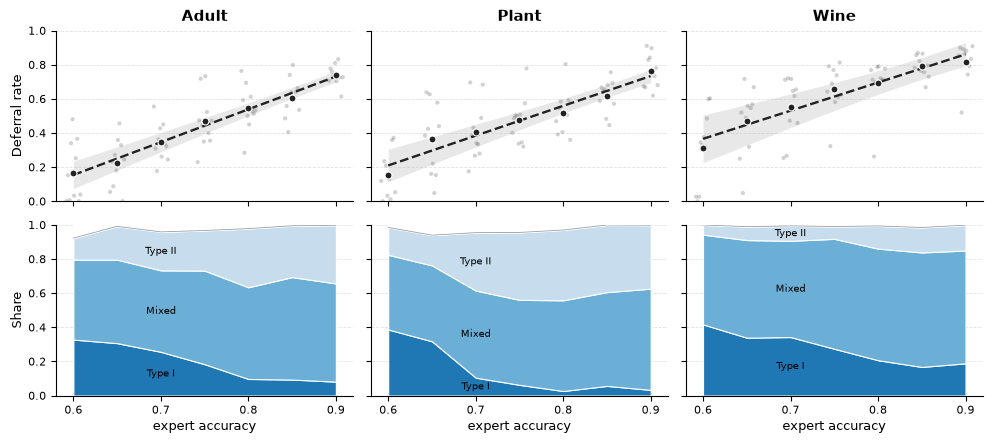

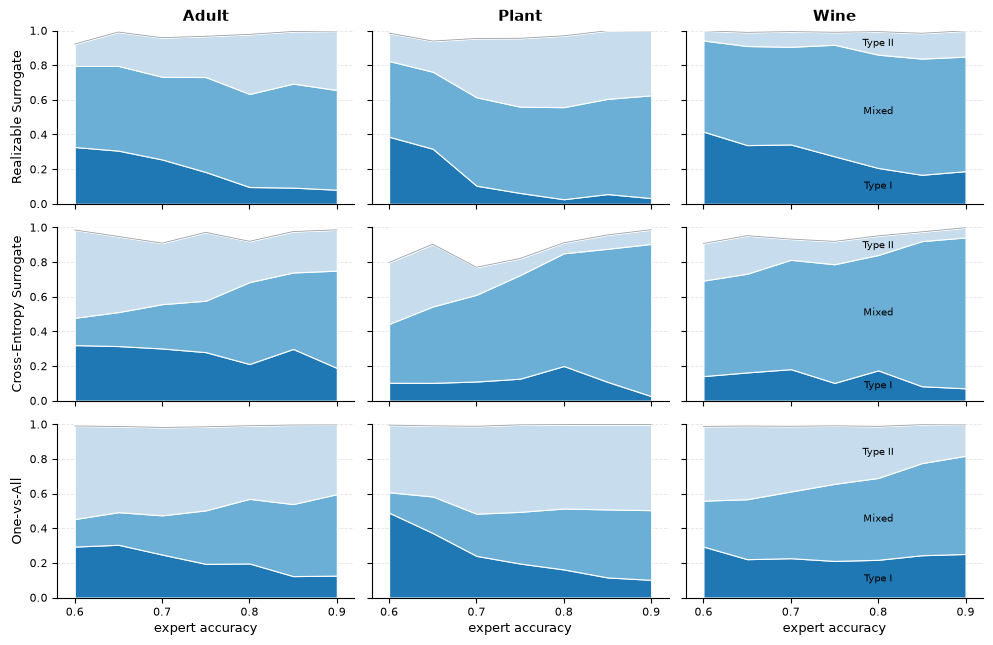

In [9]:
plt.rcParams.update({
    "font.size": 9, "axes.titlesize": 11, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "legend.fontsize": 8, "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42, "ps.fonttype": 42,
})
BLACK, GRAY = "#222222", "#D9D9D9"
CATEGORIES = [("type_i", "Type I", "#1F77B4"), ("mixed", "Mixed", "#6BAED6"),
              ("type_ii", "Type II", "#C7DDED"), ("neither", "Neither", "#FFFFFF")]


def style_axis(ax):
    ax.set_xlim(0.58, 0.92)
    ax.set_ylim(0.0, 1.0)
    ax.set_xticks([0.6, 0.7, 0.8, 0.9])
    ax.set_yticks(np.linspace(0.0, 1.0, 6))
    ax.grid(axis="y", linestyle="--", linewidth=0.6, alpha=0.35)
    ax.set_axisbelow(True)
    ax.margins(x=0)


def plot_composition(ax, frame, label_x=None):
    """Stacked mean shares of the exclusive deferral types across seeds."""
    columns = [c for c, _, _ in CATEGORIES]
    means = frame.groupby("accuracy", as_index=False)[columns].mean().sort_values("accuracy")
    x, values = means["accuracy"].to_numpy(float), means[columns].to_numpy(float)
    assert np.allclose(values.sum(axis=1), 1.0, atol=1e-6)
    ax.stackplot(x, *values.T, colors=[c for _, _, c in CATEGORIES], edgecolor="white", linewidth=0.8)
    ax.plot(x, values[:, :-1].sum(axis=1), color="#9AA0A6", linewidth=0.6)
    if label_x is not None:
        at = np.array([np.interp(label_x, x, values[:, i]) for i in range(values.shape[1])])
        for i, (_, label, _) in enumerate(CATEGORIES[:3]):
            ax.text(label_x, at[:i].sum() + at[i] / 2, label, ha="center", va="center", fontsize=7.5, clip_on=True)
    style_axis(ax)


def plot_deferral_rate(ax, frame):
    """Seed-level deferral rates, their means, and the mean within-seed linear fit with a 95% band."""
    seeds = sorted(frame["seed"].unique())
    offsets = dict(zip(seeds, np.linspace(-0.008, 0.008, len(seeds))))
    ax.scatter(frame["accuracy"] + frame["seed"].map(offsets), frame["deferral_rate"], s=9, color=BLACK,
               alpha=0.20, edgecolors="none", zorder=1)
    grid = np.linspace(0.60, 0.90, 120)
    fits = np.array([np.polyval(np.polyfit(g["accuracy"].to_numpy(float), g["deferral_rate"].to_numpy(float), 1), grid)
                     for _, g in frame.groupby("seed")])
    mean, half = fits.mean(axis=0), stats.t.ppf(0.975, df=len(fits) - 1) * stats.sem(fits, axis=0)
    ax.fill_between(grid, np.clip(mean - half, 0, 1), np.clip(mean + half, 0, 1), color=GRAY, alpha=0.58, linewidth=0, zorder=0)
    ax.plot(grid, mean, color=BLACK, linestyle="--", linewidth=1.7, zorder=2)
    means = frame.groupby("accuracy", as_index=False)["deferral_rate"].mean()
    ax.scatter(means["accuracy"], means["deferral_rate"], s=25, facecolor=BLACK, edgecolor="white", linewidth=0.8, zorder=3)
    style_axis(ax)


# fig:expert_validation_rs (Realizable Surrogate).
fig, axes = plt.subplots(2, 3, figsize=(10.0, 4.6), sharex=True, sharey="row")
for column, d in enumerate(core.DATASETS):
    frame = select("realizable_surrogate", d)
    axes[0, column].set_title(core.DATASET_LABELS[d], fontweight="bold", pad=7)
    plot_deferral_rate(axes[0, column], frame)
    plot_composition(axes[1, column], frame, label_x=0.70)
    axes[1, column].set_xlabel("expert accuracy", labelpad=3)
axes[0, 0].set_ylabel("Deferral rate", labelpad=3)
axes[1, 0].set_ylabel("Share", labelpad=3)
fig.tight_layout(rect=(0, 0, 1, 0.98), w_pad=1.0, h_pad=1.0)
fig.savefig(OUT / "realizable_surrogate_validation.pdf", bbox_inches="tight")
plt.show()

# Appendix: type composition for every loss.
fig, axes = plt.subplots(3, 3, figsize=(10.0, 6.8), sharex=True, sharey=True)
for row, m in enumerate(core.METHODS):
    for column, d in enumerate(core.DATASETS):
        plot_composition(axes[row, column], select(m, d), label_x=0.80 if column == 2 else None)
        axes[0, column].set_title(core.DATASET_LABELS[d], fontweight="bold", pad=7)
    axes[row, 0].set_ylabel(core.METHOD_LABELS[m], labelpad=4)
for ax in axes[-1]:
    ax.set_xlabel("expert accuracy", labelpad=3)
fig.tight_layout(rect=(0, 0, 1, 0.96), w_pad=1.0, h_pad=1.0)
fig.savefig(OUT / "defer_type_composition_all_methods.pdf", bbox_inches="tight")
plt.show()